# Lab13 — Static Forecasting and Forecast Evaluation
**ATSE · Final · 26 October 2026**  
**Miguel A. Arranz, PhD**

**Question.** How do forecasts change as observations arrive, and what evidence supports choosing between competing forecasting models?

Lab12 studied dynamic multi-step forecasts and conditional interventions. Here we evaluate successive **one-step forecasts**, updating the information set while keeping parameters fixed within each evaluation period. Forecasting-Tools supplies the static forecasting, accuracy and testing APIs. Model comparisons are conditional on the stated evaluation design and inference assumptions.

## 1. Design before inspecting performance

We retain monthly INDPRO log growth, $g_t=100[\log(I_t)-\log(I_{t-1})]$.

| Experiment | Training | Evaluation | Purpose |
|---|---|---|---|
| Main | January 1990–December 2012 (276 months) | January 2013–December 2019 (84 months) | Accuracy and formal evaluation |
| Stress illustration | January 1990–December 2019 (360 months) | January–December 2020 (12 months) | Descriptive evidence under an extraordinary disturbance |

The main evaluation exceeds the agreed minimum of 60 observations, and training exceeds 120. The short stress illustration is **not** used for the formal tests.

Six specifications are declared in advance: ARIMA(4,0,0), ARIMA(1,0,2) and ARIMA(1,0,3), each with a constant, **both without and with the three historical AO regressors used in Lab12** (1998-08, 2005-09, 2008-09). This allows comparison under both historical-intervention treatments; we can discuss the preferred presentation later. No hypothetical future interventions are introduced.

All evaluation results use identical dates. We do not select a model using this evaluation sample and then pretend its tests were specified independently. Data are a current revised FRED vintage: these are pseudo-out-of-sample experiments, not real-time vintage forecasts. Monthly growth at the previous date is assumed known at each origin; actual release delays are not modeled.

## 2. Environment and inspected APIs

The next cell supports a fresh Google Colab/Jupyter runtime. Skip it when dependencies are already available. Forecasting-Tools is currently a standalone module: the import cell loads an exact repository commit and verifies its source hash, instead of assuming an unverified package version. A matching local copy is used when available; otherwise the same module is downloaded into a temporary folder. No repository source files are changed.

In [1]:
%pip -q install "numpy>=2,<3" "pandas>=2.2.2,<3" "scipy>=1.13,<2" "statsmodels>=0.14.6,<0.16" matplotlib pandas_datareader

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from statsmodels.tsa.arima.model import ARIMA
from pandas_datareader import data as web
from IPython.display import display
from pathlib import Path
import sys, json, hashlib, tempfile, urllib.request, importlib.util
import importlib.metadata as metadata
import inspect, warnings

FT_COMMIT = "c3d7af5ba3dc19e2773be10c2dcc14ae7034860c"
FT_SHA256 = "4ff26832ee88bf3f4e1b60ba85ac63358b95b1b0934391d0ad7e9fd7a70f017e"
local = Path("/Users/maarranz/GitHub/Forecasting-Tools/forecasting_tools.py")
if local.is_file() and hashlib.sha256(local.read_bytes()).hexdigest() == FT_SHA256:
    module_path = local
else:
    module_path = Path(tempfile.mkdtemp(prefix="lab13_ft_"))/"forecasting_tools.py"
    url = f"https://raw.githubusercontent.com/maarranz/Forecasting-Tools/{FT_COMMIT}/forecasting_tools.py"
    module_path.write_bytes(urllib.request.urlopen(url, timeout=60).read())
assert hashlib.sha256(module_path.read_bytes()).hexdigest() == FT_SHA256
spec = importlib.util.spec_from_file_location("forecasting_tools", module_path)
ft = importlib.util.module_from_spec(spec)
spec.loader.exec_module(ft)
print("Python:", sys.version)
print("Package versions:", {p:metadata.version(p) for p in
       ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "pandas_datareader"]})
print("Forecasting-Tools commit:", FT_COMMIT, "| SHA256:", FT_SHA256)
for name in ["static_forecast", "unbiasedness_test", "weak_efficiency_test",
             "orthogonality_test", "dm_test", "mgn_test", "encompassing_test"]:
    print(name, inspect.signature(getattr(ft, name)))
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_rows", 60)
plt.rcParams.update({"figure.dpi":100, "axes.spines.top":False, "axes.spines.right":False})

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Package versions: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scipy': '1.16.3', 'statsmodels': '0.15.0', 'matplotlib': '3.10.0', 'pandas_datareader': '0.11.1'}
Forecasting-Tools commit: c3d7af5ba3dc19e2773be10c2dcc14ae7034860c | SHA256: 4ff26832ee88bf3f4e1b60ba85ac63358b95b1b0934391d0ad7e9fd7a70f017e
static_forecast (results, actual, level=0.95, *, exog=None)
unbiasedness_test (actual, forecast, method='mean_error', cov_type='HAC', maxlags=None, alpha=0.05)
weak_efficiency_test (actual, forecast, h=1, lags=10, alpha=0.05)
orthogonality_test (actual, forecast, information, h=1, cov_type='HAC', maxlags=None, alpha=0.05)
dm_test (actual, forecast1, forecast2, loss='squared', h=1, alternative='two-sided', maxlags=None, hln=False, alpha=0.05)
mgn_test (actual, forecast1, forecast2, cov_type='HAC', maxlags=None, alpha=0.05)
encompassing_test (actual, forecast1, forecast2, method='difference', direction='1_encompasses_2', include_intercept

## 3. Data and historical regressors

Historical AO coefficients are estimated using training observations only. All their future values are zero. We do not identify new outliers using evaluation outcomes. The fitted constant is supplied by statsmodels, not duplicated in the exogenous matrix.

FRED retrieval timestamp (UTC): 2026-10-26T17:18:48.194331+00:00


,Training n,Evaluation n
Main 2013–2019,276,84
Stress 2020 (descriptive only),360,12


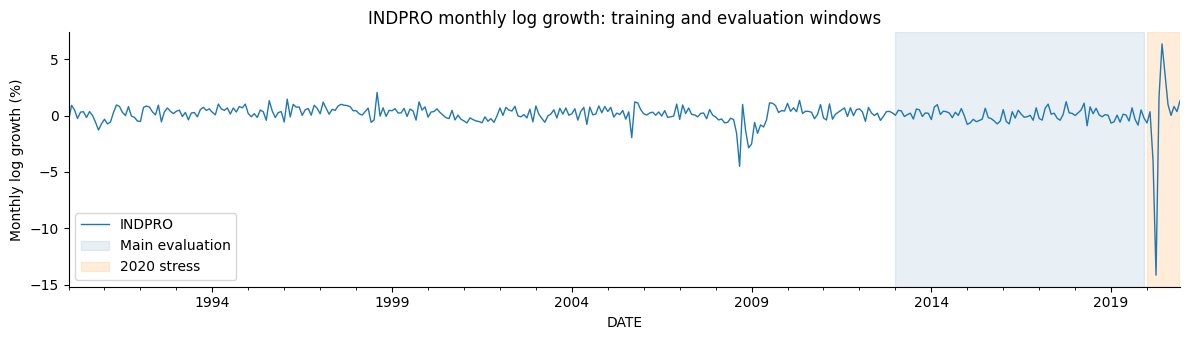

In [3]:
indpro = web.DataReader("INDPRO", "fred", start="1989-12-01", end="2020-12-31")["INDPRO"].dropna()
indpro.index = indpro.index.to_period("M").to_timestamp()
indpro = indpro.asfreq("MS")
assert indpro.notna().all() and (indpro > 0).all()
growth = (100*np.log(indpro).diff()).loc["1990-01":"2020-12"].dropna()
assert len(growth) == 372 and growth.index.is_unique
EVENTS = ("1998-08", "2005-09", "2008-09")
AO_COLS = ("AO_1998_08", "AO_2005_09", "AO_2008_09")
def historical_aos(index):
    x = pd.DataFrame(0.0, index=index, columns=AO_COLS)
    for event, col in zip(EVENTS, AO_COLS):
        x.loc[index.to_period("M")==pd.Period(event), col] = 1.0
    return x

train = growth.loc[:"2012-12"]
actual = growth.loc["2013-01":"2019-12"]
stress_train = growth.loc[:"2019-12"]
stress_actual = growth.loc["2020-01":"2020-12"]
assert len(train)==276 and len(actual)==84 and len(stress_train)==360
assert len(train)>120 and len(actual)>=60
print("FRED retrieval timestamp (UTC):", pd.Timestamp.now(tz="UTC").isoformat())
display(pd.DataFrame({"Training n":[len(train),len(stress_train)],
                      "Evaluation n":[len(actual),len(stress_actual)]},
                     index=["Main 2013–2019", "Stress 2020 (descriptive only)"]))
fig, ax = plt.subplots(figsize=(12,3.5))
growth.plot(ax=ax, lw=1)
ax.axvspan(actual.index[0], actual.index[-1], color="steelblue", alpha=.12, label="Main evaluation")
ax.axvspan(stress_actual.index[0], stress_actual.index[-1], color="darkorange", alpha=.15, label="2020 stress")
ax.set(title="INDPRO monthly log growth: training and evaluation windows", ylabel="Monthly log growth (%)")
ax.legend(); plt.tight_layout(); plt.show()

## 4. Fit the six predeclared models

ARIMA(4,0,0) is the Lab12 AR(4); the competing ARIMA(1,0,2) and ARIMA(1,0,3) introduce MA dynamics. AR/MA stationarity and invertibility constraints are retained. AIC/BIC describe training fit and are not used to redefine the predeclared evaluation comparison. Convergence and any estimation warnings are reported explicitly.

In [4]:
ORDERS = {"AR4":(4,0,0), "ARMA12":(1,0,2), "ARMA13":(1,0,3)}
SPECS = {label+(" +AO" if ao else ""): (order, ao)
         for label,order in ORDERS.items() for ao in (False,True)}
estimation_warnings = []
def fit_models(y, experiment):
    results, rows = {}, []
    for name,(order,ao) in SPECS.items():
        x = historical_aos(y.index) if ao else None
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            result = ARIMA(y, order=order, trend="c", exog=x).fit(method_kwargs={"maxiter":1000})
        for w in caught:
            estimation_warnings.append({"Experiment":experiment,"Model":name,
                                        "Category":w.category.__name__,"Message":str(w.message)})
        assert result.mle_retvals["converged"], f"Nonconvergence: {experiment}, {name}"
        assert np.isfinite(result.params).all()
        results[name]=result
        rows.append({"Model":name,"Order":str(order),"Historical AOs":ao,
                     "n":len(y),"AIC":result.aic,"BIC":result.bic,
                     "Converged":result.mle_retvals["converged"],
                     "Min AR root modulus":np.min(np.abs(result.arroots)) if len(result.arroots) else np.nan,
                     "Min MA root modulus":np.min(np.abs(result.maroots)) if len(result.maroots) else np.nan})
    return results, pd.DataFrame(rows).set_index("Model")
models, fit_table = fit_models(train, "Main")
display(fit_table.round(4))
if estimation_warnings: display(pd.DataFrame(estimation_warnings))
else: print("No estimation warnings in main-sample fits.")

,Order,Historical AOs,n,AIC,BIC,Converged,Min AR root modulus,Min MA root modulus
Model,,,,,,,,
AR4,"(4, 0, 0)",False,276,504.1117,525.8341,True,1.1649,NaN
AR4 +AO,"(4, 0, 0)",True,276,434.4460,467.0296,True,1.2279,NaN
ARMA12,"(1, 0, 2)",False,276,506.7043,524.8063,True,1.1695,2.2441
ARMA12 +AO,"(1, 0, 2)",True,276,433.8350,462.7982,True,1.2147,2.3180
ARMA13,"(1, 0, 3)",False,276,503.3825,525.1049,True,1.2908,1.4772
ARMA13 +AO,"(1, 0, 3)",True,276,433.7874,466.3710,True,1.3813,1.6527


No estimation warnings in main-sample fits.


## 5. Successive one-step forecasts, with fixed parameters

At the December 2012 origin forecast January 2013. Only after issuing that forecast, incorporate the January actual, forecast February and repeat. Forecasting-Tools appends actual observations with `refit=False`. Coefficients remain fixed; observed growth and innovations are updated.

The returned schema is `Actual`, `Forecast`, `Error`, `SE`, `Lower`, `Upper`; errors are **actual minus forecast**. The code verifies each model against an explicit forecast-then-append loop and checks that changing a later observation cannot change an earlier forecast. This does not recreate real-time data-release vintages.

In [5]:
SCHEMA = ["Actual","Forecast","Error","SE","Lower","Upper"]
forecast_checks = []
def evaluate_models(results, target, experiment):
    evaluations = {}
    for name,result in results.items():
        ao = SPECS[name][1]
        x = historical_aos(target.index) if ao else None
        expected = pd.date_range(result.model._index[-1]+pd.offsets.MonthBegin(1), periods=len(target), freq="MS")
        pd.testing.assert_index_equal(target.index, expected, check_names=False)
        if ao:
            assert list(x.columns)==list(AO_COLS)
            assert result.model.exog_names==["const", *AO_COLS]
            pd.testing.assert_index_equal(x.index,target.index)
            assert (x.to_numpy()==0).all()
        original_params = np.asarray(result.params).copy()
        original_nobs = result.nobs
        ev = ft.static_forecast(result, target, level=.95, exog=x)
        assert list(ev.columns)==SCHEMA
        pd.testing.assert_index_equal(ev.index,target.index)
        np.testing.assert_allclose(ev.Actual,target)
        np.testing.assert_allclose(ev.Error,ev.Actual-ev.Forecast)
        assert np.isfinite(ev.to_numpy()).all() and (ev.SE>0).all()
        np.testing.assert_allclose(ev.Lower,ev.Forecast-norm.ppf(.975)*ev.SE)
        np.testing.assert_allclose(ev.Upper,ev.Forecast+norm.ppf(.975)*ev.SE)
        # Independent orchestration with the underlying fitted-model API.
        current=result; manual=[]; manual_se=[]
        for j in range(len(target)):
            xrow = x.iloc[j:j+1] if ao else None
            pred = current.get_forecast(steps=1, exog=xrow)
            manual.append(float(np.asarray(pred.predicted_mean)[0]))
            manual_se.append(float(np.asarray(pred.se_mean)[0]))
            current=current.append(target.iloc[j:j+1], exog=xrow, refit=False)
        np.testing.assert_allclose(ev.Forecast,manual,rtol=1e-11,atol=1e-11)
        np.testing.assert_allclose(ev.SE,manual_se,rtol=1e-11,atol=1e-11)
        np.testing.assert_allclose(current.params,original_params,rtol=0,atol=0)
        np.testing.assert_array_equal(result.params,original_params)
        assert result.nobs==original_nobs
        changed=target.copy(); cut=len(target)//2
        changed.iloc[cut:] += 10.0
        altered=ft.static_forecast(result,changed,level=.95,exog=x)
        np.testing.assert_allclose(ev.Forecast.iloc[:cut+1],altered.Forecast.iloc[:cut+1],atol=1e-12)
        # One-step forecasts at the first origin match ordinary fitted-model forecasts.
        np.testing.assert_allclose(ev.Forecast.iloc[0], result.forecast(1,exog=x.iloc[:1] if ao else None).iloc[0])
        evaluations[name]=ev
        forecast_checks.append({"Experiment":experiment,"Model":name,"n":len(ev),
            "Max forecast discrepancy":np.max(np.abs(ev.Forecast-np.asarray(manual))),
            "Max SE discrepancy":np.max(np.abs(ev.SE-np.asarray(manual_se))),
            "Fixed coefficients":True,"No future-data leakage":True})
    return evaluations
main = evaluate_models(models, actual, "Main")
print("Forecasting-Tools return schema:",list(main["AR4"].columns))
display(main["AR4"].head())
display(pd.DataFrame(forecast_checks))

Forecasting-Tools return schema: ['Actual', 'Forecast', 'Error', 'SE', 'Lower', 'Upper']


,Actual,Forecast,Error,SE,Lower,Upper
DATE,,,,,,
2013-01-01,0.024511,0.202129,-0.177618,0.589578,-0.953423,1.357681
2013-02-01,0.466601,0.240932,0.225669,0.589578,-0.914620,1.396484
2013-03-01,0.402049,0.222971,0.179078,0.589578,-0.932581,1.378523
2013-04-01,-0.086334,0.220132,-0.306466,0.589578,-0.935420,1.375684
2013-05-01,0.078067,0.221387,-0.143320,0.589578,-0.934165,1.376939


,Experiment,Model,n,Max forecast discrepancy,Max SE discrepancy,Fixed coefficients,No future-data leakage
0,Main,AR4,84,0.0,0.0,True,True
1,Main,AR4 +AO,84,0.0,0.0,True,True
2,Main,ARMA12,84,0.0,0.0,True,True
3,Main,ARMA12 +AO,84,0.0,0.0,True,True
4,Main,ARMA13,84,0.0,0.0,True,True
5,Main,ARMA13 +AO,84,0.0,0.0,True,True


### Actuals, static forecasts and conditional intervals

Each panel uses its model's 95% Gaussian prediction interval; parameters are treated as fixed. Intervals do not include estimation uncertainty, structural breaks or revised-data uncertainty.

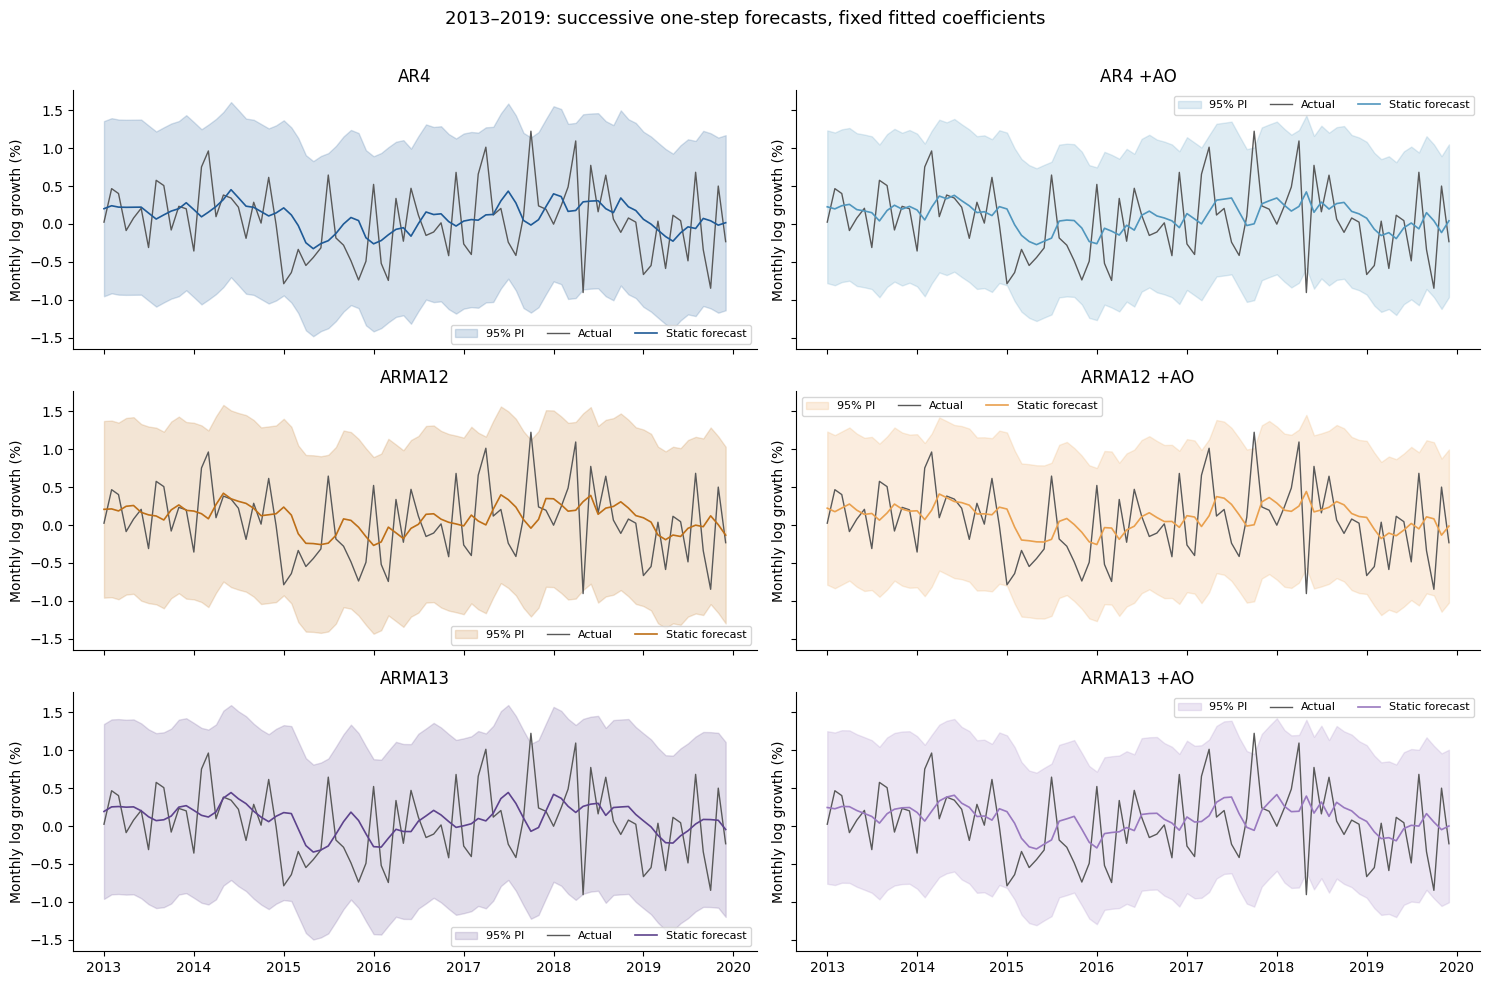

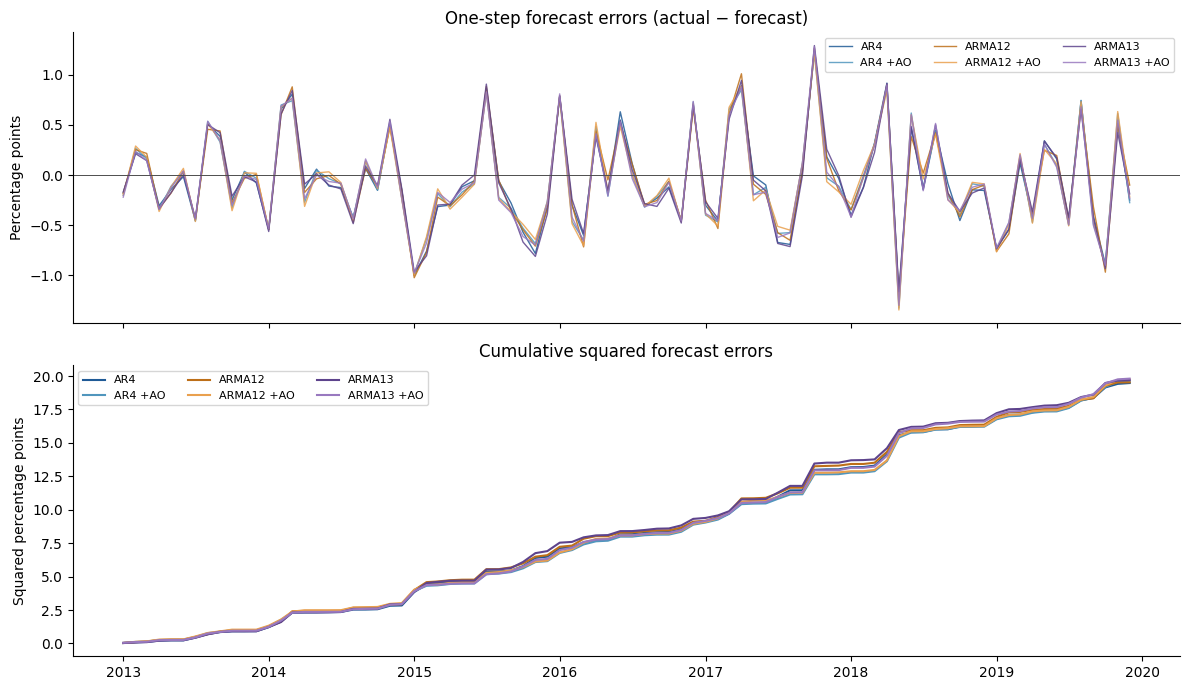

In [6]:
COLORS = {"AR4":"#1f5a96","AR4 +AO":"#5096bd","ARMA12":"#bd6f18",
          "ARMA12 +AO":"#e9a04e","ARMA13":"#5d438c","ARMA13 +AO":"#9979bf"}
fig, axes=plt.subplots(3,2,figsize=(15,10),sharex=True,sharey=True)
for ax,(name,ev) in zip(axes.flat,main.items()):
    ax.fill_between(ev.index,ev.Lower,ev.Upper,color=COLORS[name],alpha=.18,label="95% PI")
    ax.plot(ev.index,ev.Actual,color="0.35",lw=1,label="Actual")
    ax.plot(ev.index,ev.Forecast,color=COLORS[name],lw=1.2,label="Static forecast")
    ax.set(title=name,ylabel="Monthly log growth (%)")
    ax.legend(fontsize=8,ncol=3)
fig.suptitle("2013–2019: successive one-step forecasts, fixed fitted coefficients",fontsize=13)
plt.tight_layout(rect=(0,0,1,.97));plt.show()
fig,axes=plt.subplots(2,1,figsize=(12,7),sharex=True)
for name,ev in main.items():
    axes[0].plot(ev.index,ev.Error,color=COLORS[name],lw=1,alpha=.85,label=name)
    axes[1].plot(ev.index,(ev.Error**2).cumsum(),color=COLORS[name],lw=1.5,label=name)
axes[0].axhline(0,color="0.3",lw=.7)
axes[0].set(title="One-step forecast errors (actual − forecast)",ylabel="Percentage points")
axes[1].set(title="Cumulative squared forecast errors",ylabel="Squared percentage points")
axes[0].legend(ncol=3,fontsize=8);axes[1].legend(ncol=3,fontsize=8)
plt.tight_layout();plt.show()

### Updating versus a fixed-origin dynamic path

For the two AR(4) models, compare the 84 successive one-step forecasts with a single 84-month dynamic forecast issued in December 2012. Their first forecasts coincide. Thereafter the static path uses additional observations. The comparison illustrates changing information and horizons; it is not a same-horizon equal-information accuracy contest.

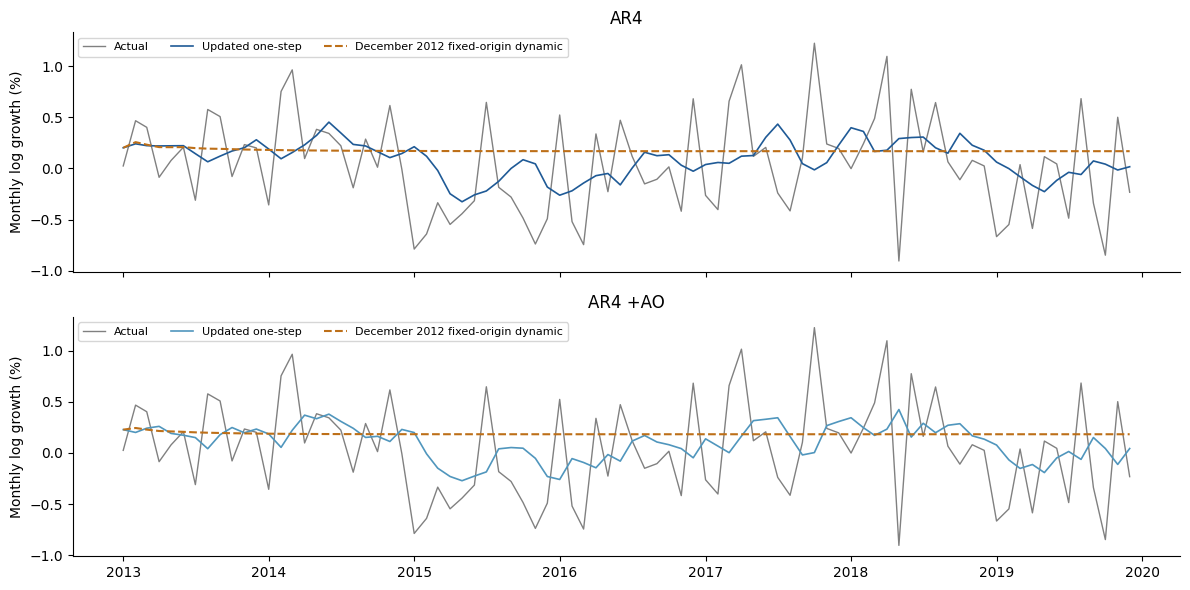

In [7]:
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True,sharey=True)
for ax,name in zip(axes,["AR4","AR4 +AO"]):
    x=historical_aos(actual.index) if SPECS[name][1] else None
    dynamic=models[name].forecast(len(actual),exog=x)
    pd.testing.assert_index_equal(dynamic.index,actual.index,check_names=False)
    np.testing.assert_allclose(dynamic.iloc[0],main[name].Forecast.iloc[0])
    ax.plot(actual.index,actual,color="0.5",label="Actual",lw=1)
    ax.plot(actual.index,main[name].Forecast,color=COLORS[name],label="Updated one-step",lw=1.2)
    ax.plot(actual.index,dynamic,color="#bd6f18",ls="--",label="December 2012 fixed-origin dynamic")
    ax.set(title=name,ylabel="Monthly log growth (%)");ax.legend(fontsize=8,ncol=3)
plt.tight_layout();plt.show()

## 6. Accuracy on identical dates

ME measures signed bias: a positive value indicates underforecasting. MAE and RMSE are in growth percentage points; MSE is in squared units. RMSE gives large misses more weight than MAE. We use the four individual Forecasting-Tools functions because `forecast_accuracy()` also computes MAPE. Percentage errors are inappropriate here: growth can be zero or near zero, and negative denominators complicate interpretation.

The table also shows empirical 95% interval coverage and mean interval width, descriptive summaries rather than formal coverage tests. Ranking by this evaluation sample is descriptive and does not independently establish a population winner.

,n,ME,MAE,MSE,RMSE,95% coverage,Mean PI width
Model,,,,,,,
AR4,84,-0.05386,0.38611,0.23185,0.48151,0.97619,2.31110
AR4 +AO,84,-0.05974,0.39143,0.23386,0.48359,0.97619,2.01557
ARMA12,84,-0.05304,0.38038,0.23250,0.48218,0.97619,2.33063
ARMA12 +AO,84,-0.05912,0.39174,0.23509,0.48486,0.97619,2.02076
ARMA13,84,-0.05811,0.38468,0.23446,0.48421,0.97619,2.30798
ARMA13 +AO,84,-0.06388,0.39279,0.23578,0.48557,0.97619,2.01305


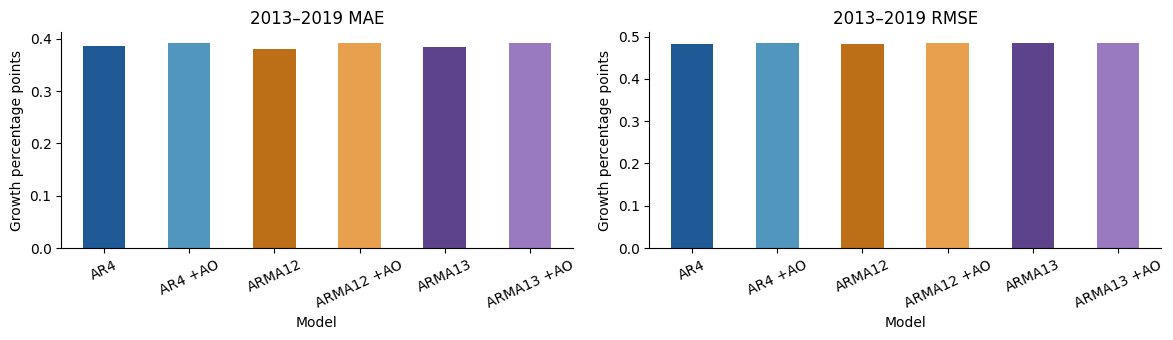

In [8]:
def accuracy_table(evaluations):
    rows=[]
    for name,ev in evaluations.items():
        values={metric:getattr(ft,metric.lower())(ev.Actual,ev.Forecast) for metric in ["ME","MAE","MSE","RMSE"]}
        error=ev.Actual-ev.Forecast
        expected=[error.mean(),error.abs().mean(),(error**2).mean(),np.sqrt((error**2).mean())]
        np.testing.assert_allclose(list(values.values()),expected,rtol=1e-12,atol=1e-12)
        rows.append({"Model":name,"n":len(ev),**values,
                     "95% coverage":((ev.Actual>=ev.Lower)&(ev.Actual<=ev.Upper)).mean(),
                     "Mean PI width":(ev.Upper-ev.Lower).mean()})
    return pd.DataFrame(rows).set_index("Model")
accuracy=accuracy_table(main)
display(accuracy.round(5))
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for ax,metric in zip(axes,["MAE","RMSE"]):
    accuracy[metric].plot.bar(ax=ax,color=[COLORS[x] for x in accuracy.index],rot=25)
    ax.set(title=f"2013–2019 {metric}",ylabel="Growth percentage points")
plt.tight_layout();plt.show()

## 7. Unbiasedness, calibration and efficiency diagnostics

The main evaluation has 84 consecutive one-step errors. We use 5% significance and an explicit Bartlett/Newey–West HAC bandwidth of 3 months (the package's automatic rule for $n=84$). This is a declared practical choice, not a claim that the bandwidth is optimal.

- **Mean error:** $H_0:E(e_t)=0$; HAC asymptotic normal inference.
- **Mincer–Zarnowitz:** $g_t=a+b\hat g_{t|t-1}+u_t$, jointly test $(a,b)=(0,1)$; HAC Wald chi-square with two restrictions.
- **Weak efficiency:** Ljung–Box at lag 10 tests zero error autocorrelations through lag 10 for these one-step errors. This diagnostic is not proof of efficiency.
- **Origin-information orthogonality:** regress errors on a constant and $g_{t-1}$, jointly testing both coefficients zero with HAC inference. The information Series is shifted **before** taking the evaluation slice; no target-month data enter it.

HAC does not automatically account for forecast-parameter estimation or repair endogeneity. These are related diagnostics, not independent discoveries. With multiple models and hypotheses, isolated 5% rejections require caution; p-values are exploratory and unadjusted. Failure to reject is not proof of unbiasedness or optimality.

In [9]:
ALPHA=.05
HAC_LAGS=3
assert HAC_LAGS==min(len(actual)-1,int(np.floor(4*(len(actual)/100)**(2/9))))
origin_information=growth.shift(1).reindex(actual.index).rename("lagged_growth")
assert origin_information.notna().all()
np.testing.assert_allclose(origin_information,growth.loc["2012-12":"2019-11"].to_numpy())
test_results={}; test_failures=[]; diagnostic_rows=[]
def checked_test(label, function, **kwargs):
    try:
        result=function(**kwargs)
        assert np.isfinite(result["statistic"]) and np.isfinite(result["pvalue"])
        assert 0<=result["pvalue"]<=1
        test_results[label]=result
        return result
    except (ValueError, np.linalg.LinAlgError) as exc:
        test_failures.append({"Test":label,"Reason":str(exc)})
        return None

for name,ev in main.items():
    tests={
        "Mean error":(ft.unbiasedness_test,dict(method="mean_error",cov_type="HAC",maxlags=HAC_LAGS)),
        "Mincer–Zarnowitz joint":(ft.unbiasedness_test,dict(method="mincer_zarnowitz",cov_type="HAC",maxlags=HAC_LAGS)),
        "Ljung–Box lag 10":(ft.weak_efficiency_test,dict(h=1,lags=10)),
        "Origin orthogonality":(ft.orthogonality_test,dict(information=origin_information,h=1,cov_type="HAC",maxlags=HAC_LAGS)),
    }
    for test,(function,options) in tests.items():
        result=checked_test(f"{name}: {test}",function,actual=ev.Actual,forecast=ev.Forecast,alpha=ALPHA,**options)
        diagnostic_rows.append({"Model":name,"Test":test,"Status":"OK" if result else "Invalid",
          "Statistic":result["statistic"] if result else np.nan,
          "p-value":result["pvalue"] if result else np.nan,
          "Reject 5%":result["reject_null"] if result else None,
          "Distribution":result.get("distribution") if result else None,
          "HAC lags":result.get("maxlags") if result else None,
          "Coefficients":{k:round(v,6) for k,v in result.get("parameters",{}).items()} if result else None})
diagnostics=pd.DataFrame(diagnostic_rows)
print("Representative diagnostics: AR(4), no historical AOs. Full six-model results are retained in the appendix.")
display(diagnostics.loc[diagnostics.Model=="AR4"].round(5))
mean_p=float(diagnostics.loc[(diagnostics.Model=="AR4")&(diagnostics.Test=="Mean error"),"p-value"].iloc[0])
mz_p=float(diagnostics.loc[(diagnostics.Model=="AR4")&(diagnostics.Test=="Mincer–Zarnowitz joint"),"p-value"].iloc[0])
print(f"AR(4) mean-error p={mean_p:.5f}; joint MZ p={mz_p:.5f}.")
print("Mean-error non-rejection concerns average error only; MZ tests both the intercept and forecast slope.")
print("Ljung–Box concerns serial correlation; origin orthogonality concerns the particular lagged-growth information supplied.")

Representative diagnostics: AR(4), no historical AOs. Full six-model results are retained in the appendix.


,Model,Test,Status,Statistic,p-value,Reject 5%,Distribution,HAC lags,Coefficients
0,AR4,Mean error,OK,-1.18249,0.23701,False,normal,3.0,{'intercept': -0.053858}
1,AR4,Mincer–Zarnowitz joint,OK,9.81478,0.00739,True,chi2,3.0,"{'intercept': -0.000547, 'slope': 0.434185}"
2,AR4,Ljung–Box lag 10,OK,17.19166,0.07023,False,chi2,NaN,{}
3,AR4,Origin orthogonality,OK,2.27509,0.32061,False,chi2,3.0,"{'intercept': -0.050565, 'lagged_growth': -0.071662}"


AR(4) mean-error p=0.23701; joint MZ p=0.00739.
Mean-error non-rejection concerns average error only; MZ tests both the intercept and forecast slope.
Ljung–Box concerns serial correlation; origin orthogonality concerns the particular lagged-growth information supplied.


## 8. Loss comparisons and forecast encompassing

Predeclared pairs compare AR(4) with each ARMA competitor **under the same historical-AO treatment**, plus AR(4) without versus with historical AOs. No pair is chosen because it looked favorable in the evaluation sample.

**Diebold–Mariano:** $d_t=L(e_{1t})-L(e_{2t})$ and $H_0:E(d_t)=0$. Negative mean differences favor model 1. We show squared and absolute loss, $h=1$, two-sided tests, Bartlett HAC bandwidth 3 and the explicit Harvey–Leybourne–Newbold correction (`hln=True`), giving Student-$t_{83}$ inference. The correction does not solve structural instability or estimation effects. ARMA(1,2) is nested in ARMA(1,3), so we do not add a routine direct DM test for that nested pair. AR(4) with/without AO controls is also nested; its reported DM comparison is **illustrative**, and standard DM/HLN reference inference may be nonstandard. HAC and HLN do not fix that issue.

**Encompassing, both directions:**

1. Difference regression without a constant: regress the selected model's error on $f_1-f_2$, testing coefficient zero. The sign of the difference is retained in both directions.
2. Unrestricted regression $g_t=a_0+a_1f_{1t}+a_2f_{2t}+u_t$: jointly test $(a_1,a_2)=(1,0)$ or $(0,1)$, leaving $a_0$ unrestricted. These are two-restriction Wald tests, not exclusion-only or zero-intercept tests.

These specifications impose different restrictions and need not agree. Both use explicit HAC bandwidth 3. Similar forecasts can make inference fragile: we report forecast correlations, difference dispersion, design rank and standardized design condition numbers. Failed tests are retained as invalid with their reasons, never assigned invented p-values. All inference remains conditional on its assumptions and exploratory under multiple comparisons.

In [10]:
PAIRS=[("AR4","ARMA12"),("AR4","ARMA13"),
       ("AR4 +AO","ARMA12 +AO"),("AR4 +AO","ARMA13 +AO"),("AR4","AR4 +AO")]
dm_rows=[];encompass_rows=[];conditioning_rows=[]
for first,second in PAIRS:
    f1=main[first].Forecast;f2=main[second].Forecast
    X=np.column_stack([np.ones(len(actual)),f1,f2])
    standardized=np.column_stack([np.ones(len(actual)),(f1-f1.mean())/f1.std(),(f2-f2.mean())/f2.std()])
    condition=float(np.linalg.cond(standardized))
    conditioning_rows.append({"Model 1":first,"Model 2":second,"Correlation":f1.corr(f2),
       "SD forecast difference":(f1-f2).std(),"Design rank":np.linalg.matrix_rank(X),
       "Standardized condition number":condition,"Conditioning flag":condition>1e4})
    nested=first=="AR4" and second=="AR4 +AO"
    for loss in ["squared","absolute"]:
        label=f"DM {loss}: {first} vs {second}"
        r=checked_test(label,ft.dm_test,actual=actual,forecast1=f1,forecast2=f2,
                      loss=loss,h=1,alternative="two-sided",maxlags=HAC_LAGS,hln=True,alpha=ALPHA)
        dm_rows.append({"Model 1":first,"Model 2":second,"Loss":loss,
          "Mean loss difference":r["mean_loss_diff"] if r else np.nan,
          "Statistic":r["statistic"] if r else np.nan,"p-value":r["pvalue"] if r else np.nan,
          "Reject 5%":r["reject_null"] if r else None,"Status":"OK" if r else "Invalid",
          "Nested-model caveat":nested,"HAC lags":HAC_LAGS,"HLN":True,
          "Distribution":r["distribution"] if r else None,"df":r["df"] if r else None})
    for method in ["difference","unrestricted"]:
        for direction in ["1_encompasses_2","2_encompasses_1"]:
            r=checked_test(f"Encompassing {method} {direction}: {first}/{second}",ft.encompassing_test,
                   actual=actual,forecast1=f1,forecast2=f2,method=method,direction=direction,
                   include_intercept=False,maxlags=HAC_LAGS,alpha=ALPHA)
            encompass_rows.append({"Model 1":first,"Model 2":second,"Method":method,
              "Direction":direction,"Status":"OK" if r else "Invalid",
              "Statistic":r["statistic"] if r else np.nan,"p-value":r["pvalue"] if r else np.nan,
              "Reject 5%":r["reject_null"] if r else None,
              "Distribution":r["distribution"] if r else None,"HAC lags":HAC_LAGS,
              "Coefficients":{k:round(v,6) for k,v in r["parameters"].items()} if r else None})
conditioning=pd.DataFrame(conditioning_rows)
dm_table=pd.DataFrame(dm_rows)
encompassing=pd.DataFrame(encompass_rows)
print("Representative comparison: AR(4) (model 1) versus ARMA(1,2) (model 2), neither with AOs.")
representative=(dm_table["Model 1"]=="AR4")&(dm_table["Model 2"]=="ARMA12")
display(accuracy.loc[["AR4","ARMA12"],["MAE","MSE","RMSE"]].round(6))
display(dm_table.loc[representative].round(6))
print("A smaller sample loss does not establish a population loss difference; interpret the DM null and p-value.")
representative_encompass=(encompassing["Model 1"]=="AR4")&(encompassing["Model 2"]=="ARMA12")
display(encompassing.loc[representative_encompass].round(6))
print("Difference-based and unrestricted tests impose distinct restrictions. Non-rejection in both directions is not proof of mutual encompassing.")
print("Rejection in both directions does not prove that a forecast combination would improve accuracy.")
print("Complete conditioning, DM and encompassing tables follow in the appendix.")
if test_failures: display(pd.DataFrame(test_failures))
else: print("All declared formal tests returned finite results; none was forced through an invalid design.")

Representative comparison: AR(4) (model 1) versus ARMA(1,2) (model 2), neither with AOs.


,MAE,MSE,RMSE
Model,,,
AR4,0.386108,0.231849,0.481507
ARMA12,0.380377,0.232501,0.482183


,Model 1,Model 2,Loss,Mean loss difference,Statistic,p-value,Reject 5%,Status,Nested-model caveat,HAC lags,HLN,Distribution,df
0,AR4,ARMA12,squared,-0.000651,-0.129482,0.897290,False,OK,False,3,True,t,83
1,AR4,ARMA12,absolute,0.005731,0.973814,0.332978,False,OK,False,3,True,t,83


A smaller sample loss does not establish a population loss difference; interpret the DM null and p-value.


,Model 1,Model 2,Method,Direction,Status,Statistic,p-value,Reject 5%,Distribution,HAC lags,Coefficients
0,AR4,ARMA12,difference,1_encompasses_2,OK,-0.649347,0.516114,False,normal,3,{'forecast_difference': -0.416487}
1,AR4,ARMA12,difference,2_encompasses_1,OK,0.909760,0.362949,False,normal,3,{'forecast_difference': 0.583513}
2,AR4,ARMA12,unrestricted,1_encompasses_2,OK,6.910011,0.031587,True,chi2,3,"{'intercept': -0.001152, 'forecast1': 0.335393, 'forecast2': 0.10613}"
3,AR4,ARMA12,unrestricted,2_encompasses_1,OK,8.229784,0.016328,True,chi2,3,"{'intercept': -0.001152, 'forecast1': 0.335393, 'forecast2': 0.10613}"


Difference-based and unrestricted tests impose distinct restrictions. Non-rejection in both directions is not proof of mutual encompassing.
Rejection in both directions does not prove that a forecast combination would improve accuracy.
Complete conditioning, DM and encompassing tables follow in the appendix.
All declared formal tests returned finite results; none was forced through an invalid design.


### 8.1 One representative Morgan–Granger–Newbold comparison

Use **model 1 = AR(4)** and **model 2 = ARMA(1,2)**, both without historical AOs, over the same 84 evaluation dates. This pair was chosen as a teaching example, not because a p-value was favorable. The models are not nested in one another; both are nevertheless estimated forecasting models.

The inspected implementation uses $e_{it}=g_t-f_{it}$, $u_t=e_{1t}+e_{2t}$ and **$v_t=e_{1t}-e_{2t}$**, and estimates

$$u_t=a+bv_t+\eta_t,\qquad H_0:b=0\quad\text{versus}\quad H_1:b\ne0.$$

The intercept $a$ is unrestricted. With $\operatorname{Var}(v)>0$, $b=0$ tests $\operatorname{Cov}(u,v)=\operatorname{Var}(e_1)-\operatorname{Var}(e_2)=0$. A positive slope/statistic indicates the first centered error variance is larger; swapping the models reverses the slope/statistic sign and retains its two-sided p-value. This is **not automatically a test of equal expected squared loss**:

$$E(e_1^2)-E(e_2^2)=\operatorname{Var}(e_1)-\operatorname{Var}(e_2)+[E(e_1)]^2-[E(e_2)]^2.$$

Both zero population error means are a sufficient assumption for the equal-MSFE interpretation; equality of squared means is the more general condition. Small sample mean errors or non-rejection of mean-error tests do not establish either population condition. DM directly tests the stated expected loss difference and therefore answers a different question from intercept-based MGN when mean errors differ.

We show **conventional OLS Student-$t_{82}$ inference**, whose classical exact reference requires independent observations and suitable Gaussian/homoskedastic regression disturbances, and **Bartlett/Newey–West HAC normal inference**, with bandwidth 3 and no small-sample covariance multiplier. HAC permits suitable weak serial dependence and heteroskedasticity but is asymptotic. Neither automatically resolves forecast-parameter estimation effects, nested-model degeneracy, structural instability or multiplicity. Do not apply MGN mechanically to nested models or every available pair.

The following code independently derives OLS coefficients, classical covariance, the Bartlett HAC sandwich, reference p-values and the classical correlation statistic. Invalid designs or covariance estimates are reported explicitly.

In [11]:
from scipy.stats import t as student_t
mgn_rows=[];mgn_validation=[]
e1=main["AR4"].Error.to_numpy()
e2=main["ARMA12"].Error.to_numpy()
u=e1+e2
v=e1-e2
N=len(u)
X=np.column_stack([np.ones(N),v])
assert np.linalg.matrix_rank(X)==2
bread=np.linalg.inv(X.T@X)
beta=np.linalg.lstsq(X,u,rcond=None)[0]
residual=u-X@beta
classical_cov=(residual@residual)/(N-2)*bread
scores=X*residual[:,None]
meat=scores.T@scores
for lag in range(1,HAC_LAGS+1):
    cross=scores[lag:].T@scores[:-lag]
    meat+=(1-lag/(HAC_LAGS+1))*(cross+cross.T)
hac_cov=bread@meat@bread
r_uv=np.corrcoef(u,v)[0,1]
correlation_t=r_uv*np.sqrt((N-2)/(1-r_uv**2))
# Identity uses centered moments consistently (population denominator N).
centered_difference=np.var(e1,ddof=0)-np.var(e2,ddof=0)
np.testing.assert_allclose(np.mean((u-u.mean())*(v-v.mean())),centered_difference,atol=1e-12)
np.testing.assert_allclose(np.mean(e1**2)-np.mean(e2**2),
                           centered_difference+e1.mean()**2-e2.mean()**2,atol=1e-12)
for covariance,manual_cov in [("nonrobust",classical_cov),("HAC",hac_cov)]:
    options=dict(cov_type=covariance,maxlags=None if covariance=="nonrobust" else HAC_LAGS)
    result=checked_test(f"MGN AR4/ARMA12 {covariance}",ft.mgn_test,
        actual=actual,forecast1=main["AR4"].Forecast,forecast2=main["ARMA12"].Forecast,
        alpha=ALPHA,**options)
    if result is None:
        mgn_rows.append({"Inference":covariance,"Status":"Invalid; see reasons table"})
        continue
    assert result["null_hypothesis"]=="slope = 0"
    manual_se=np.sqrt(np.diag(manual_cov))
    manual_stat=beta[1]/manual_se[1]
    manual_p=2*(student_t.sf(abs(manual_stat),N-2) if covariance=="nonrobust" else norm.sf(abs(manual_stat)))
    np.testing.assert_allclose([result["parameters"]["intercept"],result["parameters"]["slope"]],beta,rtol=1e-10,atol=1e-12)
    np.testing.assert_allclose([result["standard_errors"]["intercept"],result["standard_errors"]["slope"]],manual_se,rtol=1e-10,atol=1e-12)
    np.testing.assert_allclose([result["statistic"],result["pvalue"]],[manual_stat,manual_p],rtol=1e-10,atol=1e-12)
    if covariance=="nonrobust":
        np.testing.assert_allclose(result["statistic"],correlation_t,rtol=1e-10,atol=1e-12)
        assert result["distribution"]=="t" and result["df"]==N-2
    else:
        assert result["distribution"]=="normal" and result["df"] is None
        assert result["maxlags"]==HAC_LAGS
    reverse=ft.mgn_test(actual,main["ARMA12"].Forecast,main["AR4"].Forecast,alpha=ALPHA,**options)
    np.testing.assert_allclose(reverse["parameters"]["slope"],-result["parameters"]["slope"],atol=1e-12)
    np.testing.assert_allclose(reverse["statistic"],-result["statistic"],atol=1e-10)
    np.testing.assert_allclose(reverse["pvalue"],result["pvalue"],atol=1e-12)
    mgn_validation.append({"Inference":covariance,
       "Abs coefficient difference":float(np.max(np.abs(beta-np.array(list(result["parameters"].values()))))),
       "Abs statistic difference":abs(manual_stat-result["statistic"]),
       "Abs p-value difference":abs(manual_p-result["pvalue"]),"Model reversal verified":True})
    mgn_rows.append({"Model 1":"AR4","Model 2":"ARMA12","Inference":covariance,"Status":"OK",
       "Intercept":result["parameters"]["intercept"],"Slope b":result["parameters"]["slope"],
       "SE(b)":result["standard_errors"]["slope"],"Statistic":result["statistic"],
       "p-value":result["pvalue"],"Distribution":result["distribution"],"df":result["df"],
       "HAC lags":result["maxlags"],"Reject 5%":result["reject_null"]})
mgn_table=pd.DataFrame(mgn_rows)
print("Verified implementation: e=actual−forecast; u=e1+e2; v=e1−e2; unrestricted intercept; H0: slope=0.")
display(mgn_table.round(8))
display(pd.DataFrame(mgn_validation))
print("Sample means of errors:",dict(AR4=float(e1.mean()),ARMA12=float(e2.mean())))
print("Sample centered variance difference:",centered_difference)
print("Sample MSE difference (AR4 minus ARMA12):",float(np.mean(e1**2)-np.mean(e2**2)))
print("Compare these MGN results with the squared-loss DM row above: different nulls need not produce identical p-values.")
if test_failures: display(pd.DataFrame(test_failures))


Verified implementation: e=actual−forecast; u=e1+e2; v=e1−e2; unrestricted intercept; H0: slope=0.


,Model 1,Model 2,Inference,Status,Intercept,Slope b,SE(b),Statistic,p-value,Distribution,df,HAC lags,Reject 5%
0,AR4,ARMA12,nonrobust,OK,-0.107057,-0.18935,1.690026,-0.112039,0.911066,t,82.0,NaN,False
1,AR4,ARMA12,HAC,OK,-0.107057,-0.18935,1.268446,-0.149277,0.881335,normal,NaN,3.0,False


,Inference,Abs coefficient difference,Abs statistic difference,Abs p-value difference,Model reversal verified
0,nonrobust,1.942890e-16,1.249001e-16,1.110223e-16,True
1,HAC,1.942890e-16,2.220446e-16,1.110223e-16,True


Sample means of errors: {'AR4': -0.05385800465752849, 'ARMA12': -0.05304482385373197}
Sample centered variance difference: -0.0007383204611048633
Sample MSE difference (AR4 minus ARMA12): -0.0006513891330879873
Compare these MGN results with the squared-loss DM row above: different nulls need not produce identical p-values.


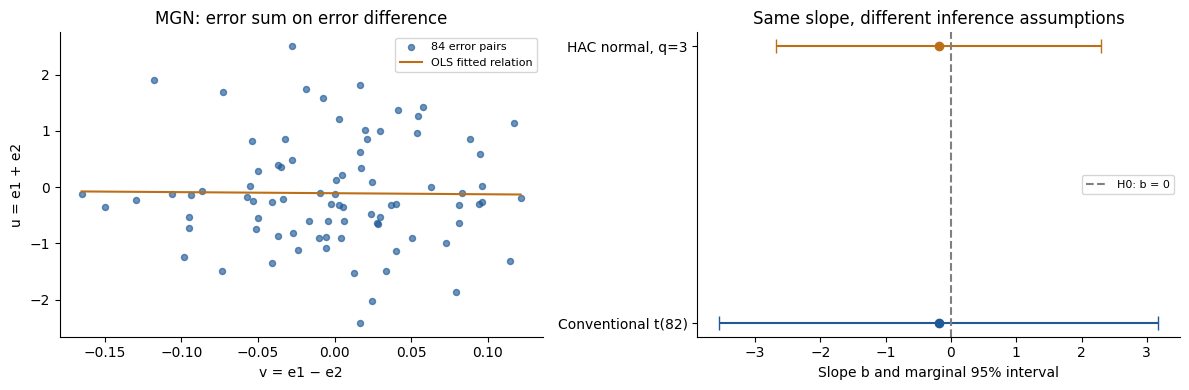

In [12]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(v,u,s=19,alpha=.65,color="#1f5a96",label="84 error pairs")
grid=np.linspace(v.min(),v.max(),100)
axes[0].plot(grid,beta[0]+beta[1]*grid,color="#bd6f18",label="OLS fitted relation")
axes[0].set(title="MGN: error sum on error difference",xlabel="v = e1 − e2",ylabel="u = e1 + e2")
axes[0].legend(fontsize=8)
for j,(covariance,manual_cov) in enumerate([("Conventional t(82)",classical_cov),("HAC normal, q=3",hac_cov)]):
    critical=student_t.ppf(.975,N-2) if j==0 else norm.ppf(.975)
    half=critical*np.sqrt(manual_cov[1,1])
    axes[1].errorbar(beta[1],j,xerr=half,fmt="o",capsize=5,color=["#1f5a96","#bd6f18"][j])
axes[1].axvline(0,color="0.5",ls="--",label="H0: b = 0")
axes[1].set(yticks=[0,1],yticklabels=["Conventional t(82)","HAC normal, q=3"],
            xlabel="Slope b and marginal 95% interval",title="Same slope, different inference assumptions")
axes[1].legend(fontsize=8)
plt.tight_layout();plt.show()


## 9. Separate 2020 stress illustration

Refit the same predeclared specifications once using January 1990–December 2019. Keep those coefficients fixed while updating with each observed 2020 growth value. No 2020 data are used to estimate the parameters or historical AO coefficients. These 12 observations provide descriptive stress evidence, not the main formal evaluation sample.

After the collapse is observed, the updating forecasts can move sharply. That is adaptation to new information, not evidence that the event was predicted beforehand. There are no hypothetical AO/LS/TC scenarios in this lab.

,Order,Historical AOs,n,AIC,BIC,Converged,Min AR root modulus,Min MA root modulus
Model,,,,,,,,
AR4,"(4, 0, 0)",False,360,624.1659,647.4825,True,1.1838,NaN
AR4 +AO,"(4, 0, 0)",True,360,550.3792,585.3542,True,1.2445,NaN
ARMA12,"(1, 0, 2)",False,360,627.1230,646.5535,True,1.1590,2.4469
ARMA12 +AO,"(1, 0, 2)",True,360,550.1027,581.1915,True,1.1870,1.8462
ARMA13,"(1, 0, 3)",False,360,623.4519,646.7685,True,1.2496,1.5453
ARMA13 +AO,"(1, 0, 3)",True,360,549.9269,584.9018,True,1.2980,1.7793


,n,ME,MAE,MSE,RMSE,95% coverage,Mean PI width
Model,,,,,,,
AR4,12,-0.02468,3.69981,29.26287,5.40952,0.33333,2.21829
AR4 +AO,12,-0.06208,3.41292,27.03356,5.19938,0.50000,1.98592
ARMA12,12,-0.00437,3.43163,29.42167,5.42417,0.50000,2.23377
ARMA12 +AO,12,-0.03414,3.23517,26.69418,5.16664,0.50000,1.99075
ARMA13,12,-0.08070,3.66137,29.41156,5.42324,0.25000,2.21609
ARMA13 +AO,12,-0.09039,3.42126,27.05544,5.20148,0.50000,1.98467


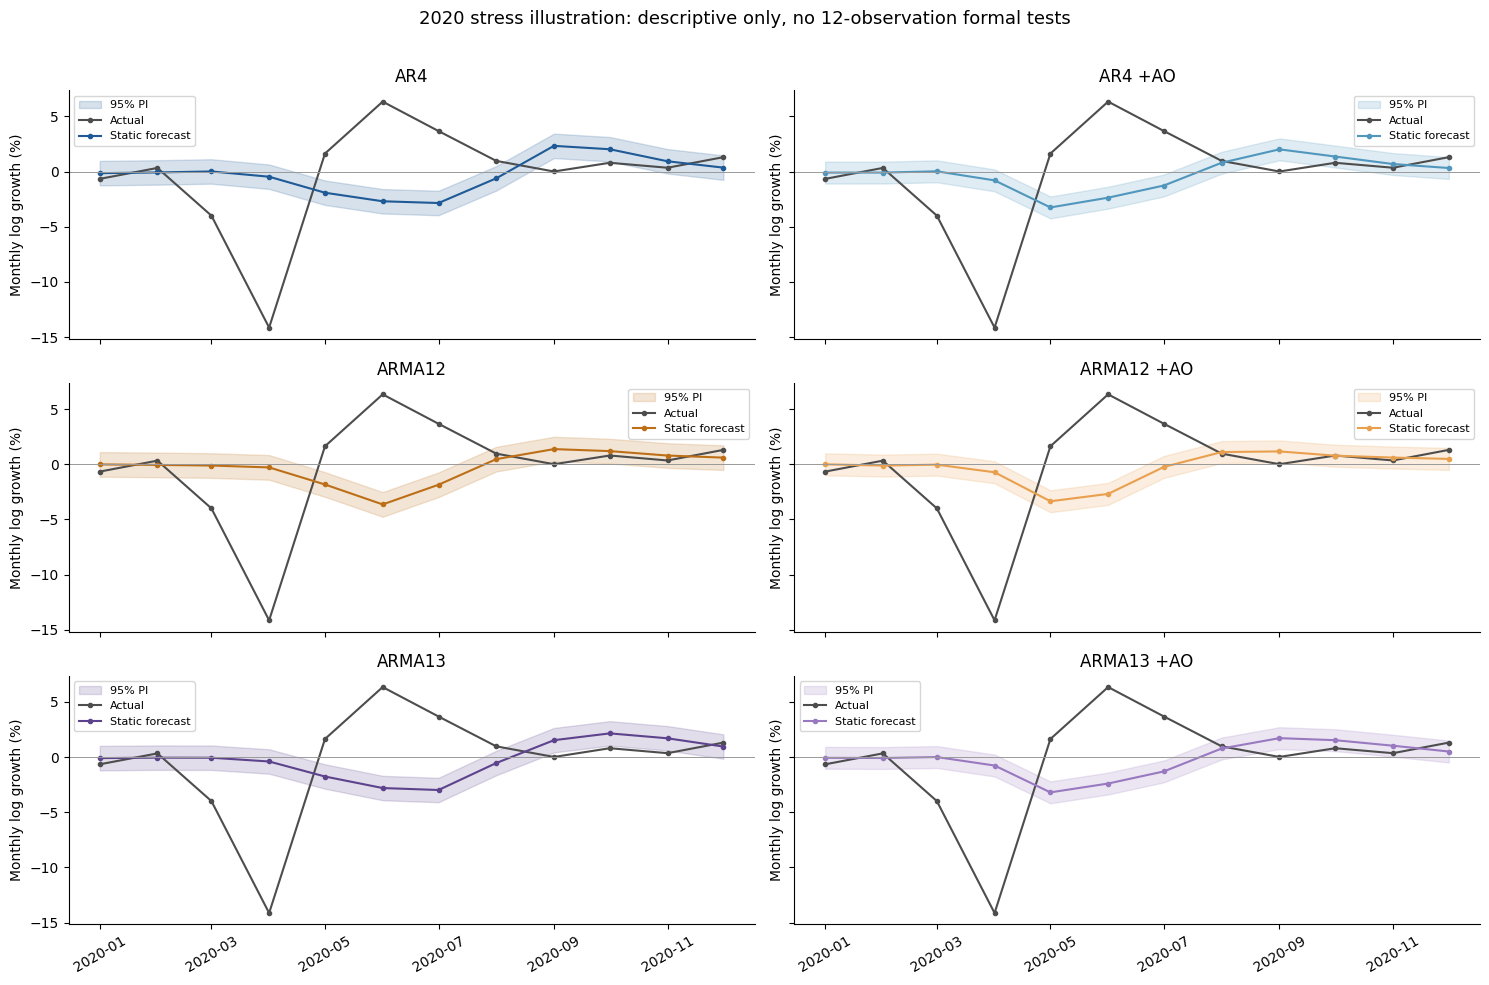

In [13]:
stress_models,stress_fit=fit_models(stress_train,"Stress")
stress=evaluate_models(stress_models,stress_actual,"Stress")
stress_accuracy=accuracy_table(stress)
display(stress_fit.round(4))
display(stress_accuracy.round(5))
fig,axes=plt.subplots(3,2,figsize=(15,10),sharex=True,sharey=True)
for ax,(name,ev) in zip(axes.flat,stress.items()):
    ax.fill_between(ev.index,ev.Lower,ev.Upper,color=COLORS[name],alpha=.18,label="95% PI")
    ax.plot(ev.index,ev.Actual,color="0.3",marker="o",ms=3,label="Actual")
    ax.plot(ev.index,ev.Forecast,color=COLORS[name],marker="o",ms=3,label="Static forecast")
    ax.axhline(0,color="0.6",lw=.7)
    ax.set(title=name,ylabel="Monthly log growth (%)")
    ax.tick_params(axis="x",labelrotation=30);ax.legend(fontsize=8)
fig.suptitle("2020 stress illustration: descriptive only, no 12-observation formal tests",fontsize=13)
plt.tight_layout(rect=(0,0,1,.97));plt.show()

## 10. Validation and questions for discussion

The checks below summarize model convergence, fixed coefficients, independent forecast/standard-error replication, forecast indexing and no-future-data-leakage checks, agreement of accuracy formulas, and validity of declared tests. Estimation warnings and invalid tests are exposed for review. Model rankings and rejections are results of this sample, not universal conclusions.

1. How do AR versus MA dynamics affect updating after an unexpected observation?
2. Does historical AO treatment improve training fit and evaluation accuracy in the same way?
3. How do MAE and RMSE rankings change when large errors receive greater weight?
4. Can a model have low mean error but fail joint calibration or orthogonality?
5. Why can neither direction of encompassing be rejected? Why can both be rejected?
6. Why might difference and unrestricted encompassing results disagree?
7. What makes a 2020 comparison informative descriptively but unreliable as a stand-alone formal test sample?
8. Which conclusions would require a further untouched evaluation sample?

We leave the final comparison presentation and any further extensions for discussion. No combinations, rolling re-estimation, new intervention scenarios or additional notebook versions are implemented.

In [14]:
checks=pd.DataFrame(forecast_checks)
display(checks)
if estimation_warnings: display(pd.DataFrame(estimation_warnings))
else: print("No estimation warnings in either experiment.")
if test_failures: display(pd.DataFrame(test_failures))
print("Main evaluation n:",len(actual),"| training n:",len(train))
print("Successful declared formal tests:",len(test_results),"| invalid tests:",len(test_failures))
print("Maximum forecast replication difference:",checks["Max forecast discrepancy"].max())
print("Maximum SE replication difference:",checks["Max SE discrepancy"].max())
print("Maximum standardized encompassing condition number:",conditioning["Standardized condition number"].max())
print("Descriptive main-sample RMSE ranking:")
display(accuracy[["RMSE","MAE"]].sort_values("RMSE").round(6))
assert checks["Fixed coefficients"].all() and checks["No future-data leakage"].all()
assert len(mgn_table)==2
assert len(dm_table)==10 and len(encompassing)==20 and len(diagnostics)==24
assert (fit_table.Converged.all() and stress_fit.Converged.all())
print("Notebook numerical validation checks passed. Execution environment and any remaining issues are reported separately.")

,Experiment,Model,n,Max forecast discrepancy,Max SE discrepancy,Fixed coefficients,No future-data leakage
0,Main,AR4,84,0.0,0.0,True,True
1,Main,AR4 +AO,84,0.0,0.0,True,True
2,Main,ARMA12,84,0.0,0.0,True,True
3,Main,ARMA12 +AO,84,0.0,0.0,True,True
4,Main,ARMA13,84,0.0,0.0,True,True
5,Main,ARMA13 +AO,84,0.0,0.0,True,True
6,Stress,AR4,12,0.0,0.0,True,True
7,Stress,AR4 +AO,12,0.0,0.0,True,True
8,Stress,ARMA12,12,0.0,0.0,True,True
9,Stress,ARMA12 +AO,12,0.0,0.0,True,True


No estimation warnings in either experiment.
Main evaluation n: 84 | training n: 276
Successful declared formal tests: 56 | invalid tests: 0
Maximum forecast replication difference: 0.0
Maximum SE replication difference: 0.0
Maximum standardized encompassing condition number: 10.623327702746918
Descriptive main-sample RMSE ranking:


,RMSE,MAE
Model,,
AR4,0.481507,0.386108
ARMA12,0.482183,0.380377
AR4 +AO,0.483592,0.391432
ARMA13,0.484213,0.384684
ARMA12 +AO,0.484856,0.391740
ARMA13 +AO,0.485572,0.392792


Notebook numerical validation checks passed. Execution environment and any remaining issues are reported separately.


### Recomputed empirical findings and comparison with executed v0.1

The next cell compares v0.2 with reference tables extracted programmatically from v0.1's saved outputs at their displayed precision. It reports the empirical conclusions from current objects, without forcing the expected rankings or rejection counts. Any change must be investigated before drawing conclusions. The 2020 observations remain descriptive and do not enter these main formal comparisons.

In [15]:
from io import StringIO
# These saved numeric reference tables are extracted from v0.1 outputs, not hand-entered findings.
REFERENCE_TABLES = {'Main training fit': '{"columns":["Order","Historical AOs","n","AIC","BIC","Converged","Min AR root modulus","Min MA root modulus"],"index":["AR4","AR4 +AO","ARMA12","ARMA12 +AO","ARMA13","ARMA13 +AO"],"data":[["(4, 0, 0)",false,276,504.1117,525.8341,true,1.1649,null],["(4, 0, 0)",true,276,434.446,467.0296,true,1.2279,null],["(1, 0, 2)",false,276,506.7043,524.8063,true,1.1695,2.2441],["(1, 0, 2)",true,276,433.835,462.7982,true,1.2147,2.318],["(1, 0, 3)",false,276,503.3825,525.1049,true,1.2908,1.4772],["(1, 0, 3)",true,276,433.7874,466.371,true,1.3813,1.6527]]}', 'Main accuracy': '{"columns":["n","ME","MAE","MSE","RMSE","95% coverage","Mean PI width"],"index":["AR4","AR4 +AO","ARMA12","ARMA12 +AO","ARMA13","ARMA13 +AO"],"data":[[84,-0.05386,0.38611,0.23185,0.48151,0.97619,2.3111],[84,-0.05974,0.39143,0.23386,0.48359,0.97619,2.01557],[84,-0.05304,0.38038,0.2325,0.48218,0.97619,2.33063],[84,-0.05912,0.39174,0.23509,0.48486,0.97619,2.02076],[84,-0.05811,0.38468,0.23446,0.48421,0.97619,2.30798],[84,-0.06388,0.39279,0.23578,0.48557,0.97619,2.01305]]}', 'Stress training fit': '{"columns":["Order","Historical AOs","n","AIC","BIC","Converged","Min AR root modulus","Min MA root modulus"],"index":["AR4","AR4 +AO","ARMA12","ARMA12 +AO","ARMA13","ARMA13 +AO"],"data":[["(4, 0, 0)",false,360,624.1659,647.4825,true,1.1838,null],["(4, 0, 0)",true,360,550.3792,585.3542,true,1.2445,null],["(1, 0, 2)",false,360,627.123,646.5535,true,1.159,2.4469],["(1, 0, 2)",true,360,550.1027,581.1915,true,1.187,1.8462],["(1, 0, 3)",false,360,623.4519,646.7685,true,1.2496,1.5453],["(1, 0, 3)",true,360,549.9269,584.9018,true,1.298,1.7793]]}', 'Stress accuracy': '{"columns":["n","ME","MAE","MSE","RMSE","95% coverage","Mean PI width"],"index":["AR4","AR4 +AO","ARMA12","ARMA12 +AO","ARMA13","ARMA13 +AO"],"data":[[12,-0.02468,3.69981,29.26287,5.40952,0.33333,2.21829],[12,-0.06208,3.41292,27.03356,5.19938,0.5,1.98592],[12,-0.00437,3.43163,29.42167,5.42417,0.5,2.23377],[12,-0.03414,3.23517,26.69418,5.16664,0.5,1.99075],[12,-0.0807,3.66137,29.41156,5.42324,0.25,2.21609],[12,-0.09039,3.42126,27.05544,5.20148,0.5,1.98467]]}'}
comparison_rows=[]
for label,current in [("Main training fit",fit_table),("Main accuracy",accuracy),
                      ("Stress training fit",stress_fit),("Stress accuracy",stress_accuracy)]:
    reference=pd.read_json(StringIO(REFERENCE_TABLES[label]),orient="split")
    cols=[col for col in reference.columns if col in current.columns and pd.api.types.is_numeric_dtype(reference[col])
          and not pd.api.types.is_bool_dtype(reference[col])]
    # v0.1 saved tables were printed to 4 or 5 decimals. Keep that precision in the comparison.
    assert len(cols)>0, f"No matched numeric columns for {label}"
    decimals=4 if "fit" in label else 5
    difference=float(np.nanmax(np.abs(current.loc[reference.index,cols].round(decimals).to_numpy(dtype=float)
                                      -reference[cols].to_numpy(dtype=float))))
    comparison_rows.append({"Comparison":label,"Max difference at v0.1 precision":difference,
                            "Matches saved v0.1":difference<=10**(-decimals)})
    if difference>10**(-decimals):
        warnings.warn(f"{label} changed: inspect data vintage, package versions and fitted parameters before interpretation.")
display(pd.DataFrame(comparison_rows))
print("Recomputed main-sample RMSE range:",float(accuracy.RMSE.min()),float(accuracy.RMSE.max()))
print("Smallest sample RMSE:",accuracy.RMSE.idxmin(),"| smallest sample MAE:",accuracy.MAE.idxmin())
for plain in ["AR4","ARMA12","ARMA13"]:
    adjusted=plain+" +AO"
    print(plain,"AO improves training AIC/BIC:",bool((fit_table.loc[adjusted,["AIC","BIC"]]<fit_table.loc[plain,["AIC","BIC"]]).all()),
          "| AO improves main RMSE:",bool(accuracy.loc[adjusted,"RMSE"]<accuracy.loc[plain,"RMSE"]))
print("Joint MZ rejections:",int(diagnostics.loc[diagnostics.Test=="Mincer–Zarnowitz joint","Reject 5%"].sum()),"of",len(main))
print("DM rejections:",int(dm_table["Reject 5%"].sum()),"of",len(dm_table))
print("Stress RMSE exceeds main RMSE for all models:",bool((stress_accuracy.RMSE>accuracy.RMSE).all()))
print("All findings above are recomputed rather than imposed by outcome assertions.")


,Comparison,Max difference at v0.1 precision,Matches saved v0.1
0,Main training fit,2.220446e-16,True
1,Main accuracy,1.110223e-16,True
2,Stress training fit,2.220446e-16,True
3,Stress accuracy,4.440892e-16,True


Recomputed main-sample RMSE range: 0.4815072574823286 0.4855720477651039
Smallest sample RMSE: AR4 | smallest sample MAE: ARMA12
AR4 AO improves training AIC/BIC: True | AO improves main RMSE: False
ARMA12 AO improves training AIC/BIC: True | AO improves main RMSE: False
ARMA13 AO improves training AIC/BIC: True | AO improves main RMSE: False
Joint MZ rejections: 6 of 6
DM rejections: 0 of 10
Stress RMSE exceeds main RMSE for all models: True
All findings above are recomputed rather than imposed by outcome assertions.


## Appendix — comprehensive numerical results

The representative narrative does not replace the full results. These tables retain all six models, all 24 original diagnostic tests, all 10 DM comparisons and all 20 encompassing tests, plus the two inference methods for the single MGN pair. Regression coefficients accompany the relevant tests. The main text defines the nulls, bandwidths and inference methods; invalid tests, if any, appear with their reasons. No p-values are screened out based on significance.

In [16]:
print("All main-sample diagnostics (HAC for regression tests; Ljung–Box chi-square at lag 10):")
display(diagnostics.round(6))
print("All comparison conditioning checks:")
display(conditioning.round(6))
print("All DM comparisons (both losses, HAC q=3, HLN correction, h=1):")
display(dm_table.round(6))
print("All encompassing comparisons (both directions, HAC q=3):")
display(encompassing.round(6))
print("Single representative MGN pair, conventional and HAC inference:")
display(mgn_table.round(8))
if test_failures: display(pd.DataFrame(test_failures))
print("Total successful declared formal tests:",len(test_results),"| invalid tests:",len(test_failures))


All main-sample diagnostics (HAC for regression tests; Ljung–Box chi-square at lag 10):


,Model,Test,Status,Statistic,p-value,Reject 5%,Distribution,HAC lags,Coefficients
0,AR4,Mean error,OK,-1.182486,0.237013,False,normal,3.0,{'intercept': -0.053858}
1,AR4,Mincer–Zarnowitz joint,OK,9.814783,0.007392,True,chi2,3.0,"{'intercept': -0.000547, 'slope': 0.434185}"
2,AR4,Ljung–Box lag 10,OK,17.191665,0.070229,False,chi2,NaN,{}
3,AR4,Origin orthogonality,OK,2.275085,0.320606,False,chi2,3.0,"{'intercept': -0.050565, 'lagged_growth': -0.071662}"
4,AR4 +AO,Mean error,OK,-1.437252,0.150646,False,normal,3.0,{'intercept': -0.059739}
5,AR4 +AO,Mincer–Zarnowitz joint,OK,11.587083,0.003047,True,chi2,3.0,"{'intercept': -0.000303, 'slope': 0.406238}"
6,AR4 +AO,Ljung–Box lag 10,OK,19.095421,0.039067,True,chi2,NaN,{}
7,AR4 +AO,Origin orthogonality,OK,6.072368,0.048018,True,chi2,3.0,"{'intercept': -0.051581, 'lagged_growth': -0.177546}"
8,ARMA12,Mean error,OK,-1.184649,0.236156,False,normal,3.0,{'intercept': -0.053045}
9,ARMA12,Mincer–Zarnowitz joint,OK,11.256070,0.003596,True,chi2,3.0,"{'intercept': 0.001015, 'slope': 0.421241}"


All comparison conditioning checks:


,Model 1,Model 2,Correlation,SD forecast difference,Design rank,Standardized condition number,Conditioning flag
0,AR4,ARMA12,0.935184,0.062819,3,5.464112,False
1,AR4,ARMA13,0.969391,0.044798,3,8.021260,False
2,AR4 +AO,ARMA12 +AO,0.981310,0.032718,3,10.296023,False
3,AR4 +AO,ARMA13 +AO,0.982434,0.032533,3,10.623328,False
4,AR4,AR4 +AO,0.909492,0.073438,3,4.593198,False


All DM comparisons (both losses, HAC q=3, HLN correction, h=1):


,Model 1,Model 2,Loss,Mean loss difference,Statistic,p-value,Reject 5%,Status,Nested-model caveat,HAC lags,HLN,Distribution,df
0,AR4,ARMA12,squared,-0.000651,-0.129482,0.897290,False,OK,False,3,True,t,83
1,AR4,ARMA12,absolute,0.005731,0.973814,0.332978,False,OK,False,3,True,t,83
2,AR4,ARMA13,squared,-0.002613,-0.533666,0.594999,False,OK,False,3,True,t,83
3,AR4,ARMA13,absolute,0.001424,0.277792,0.781863,False,OK,False,3,True,t,83
4,AR4 +AO,ARMA12 +AO,squared,-0.001224,-0.434944,0.664732,False,OK,False,3,True,t,83
5,AR4 +AO,ARMA12 +AO,absolute,-0.000307,-0.097210,0.922794,False,OK,False,3,True,t,83
6,AR4 +AO,ARMA13 +AO,squared,-0.001919,-0.507337,0.613263,False,OK,False,3,True,t,83
7,AR4 +AO,ARMA13 +AO,absolute,-0.001360,-0.354177,0.724105,False,OK,False,3,True,t,83
8,AR4,AR4 +AO,squared,-0.002012,-0.261293,0.794514,False,OK,True,3,True,t,83
9,AR4,AR4 +AO,absolute,-0.005324,-0.722078,0.472276,False,OK,True,3,True,t,83


All encompassing comparisons (both directions, HAC q=3):


,Model 1,Model 2,Method,Direction,Status,Statistic,p-value,Reject 5%,Distribution,HAC lags,Coefficients
0,AR4,ARMA12,difference,1_encompasses_2,OK,-0.649347,0.516114,False,normal,3,{'forecast_difference': -0.416487}
1,AR4,ARMA12,difference,2_encompasses_1,OK,0.909760,0.362949,False,normal,3,{'forecast_difference': 0.583513}
2,AR4,ARMA12,unrestricted,1_encompasses_2,OK,6.910011,0.031587,True,chi2,3,"{'intercept': -0.001152, 'forecast1': 0.335393, 'forecast2': 0.10613}"
3,AR4,ARMA12,unrestricted,2_encompasses_1,OK,8.229784,0.016328,True,chi2,3,"{'intercept': -0.001152, 'forecast1': 0.335393, 'forecast2': 0.10613}"
4,AR4,ARMA13,difference,1_encompasses_2,OK,0.127022,0.898923,False,normal,3,{'forecast_difference': 0.152958}
5,AR4,ARMA13,difference,2_encompasses_1,OK,0.957464,0.338333,False,normal,3,{'forecast_difference': 1.152958}
6,AR4,ARMA13,unrestricted,1_encompasses_2,OK,7.010500,0.030039,True,chi2,3,"{'intercept': -0.00072, 'forecast1': 0.3807, 'forecast2': 0.052923}"
7,AR4,ARMA13,unrestricted,2_encompasses_1,OK,7.410598,0.024593,True,chi2,3,"{'intercept': -0.00072, 'forecast1': 0.3807, 'forecast2': 0.052923}"
8,AR4 +AO,ARMA12 +AO,difference,1_encompasses_2,OK,0.059063,0.952902,False,normal,3,{'forecast_difference': 0.07856}
9,AR4 +AO,ARMA12 +AO,difference,2_encompasses_1,OK,0.810875,0.417437,False,normal,3,{'forecast_difference': 1.07856}


Single representative MGN pair, conventional and HAC inference:


,Model 1,Model 2,Inference,Status,Intercept,Slope b,SE(b),Statistic,p-value,Distribution,df,HAC lags,Reject 5%
0,AR4,ARMA12,nonrobust,OK,-0.107057,-0.18935,1.690026,-0.112039,0.911066,t,82.0,NaN,False
1,AR4,ARMA12,HAC,OK,-0.107057,-0.18935,1.268446,-0.149277,0.881335,normal,NaN,3.0,False


Total successful declared formal tests: 56 | invalid tests: 0
